In [4]:
!pip install dash

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from dash import Dash, dcc, html, Input, Output


In [5]:
df = pd.read_csv("project_1_python.csv")
df.head(5)

,index,iso_code,continent,location,date,total_cases,new_cases,total_deaths,new_deaths,hosp_patients,...,people_vaccinated,people_fully_vaccinated,total_boosters,new_vaccinations,population,median_age,gdp_per_capita,life_expectancy,latitude,longitude
0,0,AFG,Asia,Afghanistan,2020-02-24,5.0,5.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,39835428.0,18.6,1803.987,64.83,33.0,65.0
1,1,AFG,Asia,Afghanistan,2020-02-25,5.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,39835428.0,18.6,1803.987,64.83,33.0,65.0
2,2,AFG,Asia,Afghanistan,2020-02-26,5.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,39835428.0,18.6,1803.987,64.83,33.0,65.0
3,3,AFG,Asia,Afghanistan,2020-02-27,5.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,39835428.0,18.6,1803.987,64.83,33.0,65.0
4,4,AFG,Asia,Afghanistan,2020-02-28,5.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,39835428.0,18.6,1803.987,64.83,33.0,65.0


In [6]:
# Setting color pallete for continents
continent_colors = {
    "Asia": "#F58220",
    "Europe": "#4363D8",
    "Africa": "#46F0F0",
    "North America": "#BFEF45",
    "South America": "#F032E6",
    "Oceania": "#008080"
}

## Country population

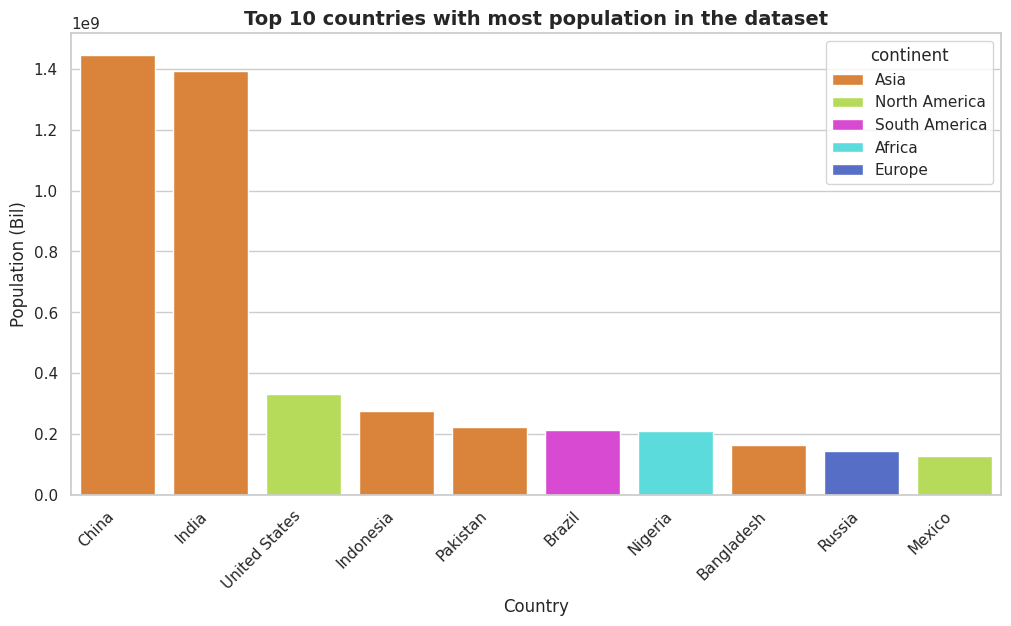

In [7]:



# Filetering Unique values in "location" column
df_countries = df.drop_duplicates(subset=["location"])

# Filtering top 10 countries based on population
population_top = df_countries.sort_values(by="population", ascending=False).head(10)

# Setting theme and size
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Creating bar chart
graf = sns.barplot(
    data=population_top,
    x="location",
    y="population",
    hue="continent",
    palette=continent_colors,
    legend=True,
)


# Rotating x axis names
plt.xticks(rotation=45, ha="right")

# Setting the title of the plot and naming the axes
plt.title("Top 10 countries with most population in the dataset", fontsize=14, fontweight="bold")
plt.xlabel("Country", fontsize=12)
plt.ylabel("Population (Bil)", fontsize=12)

plt.show()


## Population/Life expectancy correlation

In [8]:
# Creating the plot setting x to logarithmic scale
fig = px.scatter(
    df_countries,
    x="population",
    y="life_expectancy",
    color="continent",
    hover_name="location",
    log_x=True,
    title="<b>Population/Life Expectancy Correlation</b>",
    color_discrete_map=continent_colors,
    labels={
        "population": "Population",
        "life_expectancy": "Life expectancy (Years)",
        "continent": "Continent"}
)

# Changing the style for traces (Increasing marker size and formating the hover box)
fig.update_traces(
    marker=dict(size=12),
    hovertemplate="<b>%{hovertext}</b><br>"
    "Population = %{x:,.0f}<br>"
    "Life expectancy = %{y} Years<extra></extra>"
)

# Adding dropdown menu
continents = [trace.name for trace in fig.data]
traces = len(continents)
buttons = []

# Adding All continents button
buttons.append(
    dict(
        args=[{"opacity": [1.0] * traces}],  # Používáme čisté "opacity" pro celou řadu
        label="All continents",
        method="restyle"
    )
)
# Adding Buttons for the different continents
for i, continent in enumerate(continents):
    opacity = [0.2] * traces
    opacity[i] = 1.0

    buttons.append(
        dict(
            args=[{"opacity": opacity}],
            label=continent,
            method="restyle"
        )
    )

# Adjusting the plot layout
fig.update_layout(
    updatemenus=[
        dict(
            buttons=buttons,
            direction="down",
            showactive=True,
            x=1.15,
            xanchor="right",
            y=1.10,
            yanchor="top"
        )
    ],
    title_x=0.5,
    template="plotly_white",
    xaxis=dict(tickformat=".2s"),
    width=1200,
    height=750
)

fig.show()


*The scatterplot doesn't indicate that countries with larger populations have higher life expectancy. What it does show, for example, is that life expectency in Africe is lower than on the other continents.*

## number of diagnosed cases

In [9]:
df["date"] = pd.to_datetime(df["date"])

# Choosing the two countries
chosen_countries = ["Czechia", "Slovakia"]
df_compare = df[df["location"].isin(chosen_countries)].copy()

# Creating the line graph
fig_timeline = px.line(
    df_compare,
    x="date",
    y="new_cases",
    color="location",
    title="<b>Daily New COVID-19 Cases in Czechia and Slovakia over time</b>",
    color_discrete_sequence=px.colors.qualitative.Vivid,
    labels={
        "date": "Date",
        "new_cases": "New Cases per Day",
        "location": "Country",
    },
)

fig_timeline.update_layout(
    title_x=0.5,
    template="plotly_white",
    xaxis=dict(type="date"),
    yaxis=dict(tickformat=","),
    width=1200,
    height=600,
)


fig_timeline.show()

## COVID-19 map

In [10]:
# Removing rows with NaN values in total_cases column
df_filtered = df[df["total_cases"].notna()]

# Grouping by data we need for the dashboard and showing only row with the maximum value
df_total_cases = df_filtered.groupby(["location", "continent", "latitude", "longitude"]).agg({"total_cases": "max"}).reset_index()


# Creating the scattermap
fig_map = px.scatter_map(
    df_total_cases,
    lat="latitude",
    lon="longitude",
    color="continent",
    size="total_cases",
    size_max=35,
    zoom=1,
    hover_name="location",
    title="<b>Global Distribution of total COVID-19 Cases</b>",
    color_discrete_map=continent_colors
)

# Formatting the hover box
fig_map.update_traces(
    hovertemplate="<b>%{hovertext}</b><br>"
    "Total Cases = %{marker.size:,.0f}<extra></extra>"
)

# Updating the layout, using dark map
fig_map.update_layout(
    map_style="carto-darkmatter",
    title_x=0.5,
    width=1200,
    height=750,
    template="plotly_dark"
)

fig_map.show()

*We can see that the total number of cases for China is very low, which is surprising compared to it's population*

## Dashboard 1

In [11]:

# Sorting the df by date
df = df.sort_values(by="date")

# List of countries
countries_list = sorted(df["location"].unique())


app = Dash()

# Creating the dashboard
app.layout = html.Div([

    html.H1(id='dynamic-main-title', style={'textAlign': 'center', 'fontFamily': 'Arial', 'marginBottom': '20px', 'backgroundColor': '#ffffff'}),

    html.Div([
        html.Label("Select country:", style={'fontWeight': 'bold', 'fontFamily': 'Arial', 'fontSize': '16px'}),
        dcc.Dropdown(
            id='country-filter',
            options=[{'label': country, 'value': country} for country in countries_list],
            value='Czechia' if 'Czechia' in countries_list else countries_list[0],
            clearable=False,
            style={'width': '300px', 'marginTop': '5px'}
        )
    ], style={'padding': '20px', 'marginBottom': '20px', 'backgroundColor': '#ffffff'}),


    html.Div([
        html.Div([
            dcc.Graph(id='cases-line-chart')
        ], style={'width': '50%', 'display': 'inline-block'}),

        html.Div([
            dcc.Graph(id='deaths-line-chart')
        ], style={'width': '50%', 'display': 'inline-block'})
    ], style={'display': 'flex', 'flexDirection': 'row'})
])

@app.callback(
    [Output('dynamic-main-title', 'children'),
     Output('cases-line-chart', 'figure'),
     Output('deaths-line-chart', 'figure')],
    [Input('country-filter', 'value')]
)
def update_dashboard(selected_country):
    df_filtered = df[df["location"] == selected_country]

    title_text = f"Number of total cases and deaths in {selected_country}"

    # Total Cases
    fig_cases = px.line(
        df_filtered,
        x="date",
        y="total_cases",
        title=f"<b>Total Cases over Time</b>",
        labels={"date": "Date", "total_cases": "Cases"}
    )
    fig_cases.update_layout(template="plotly_white", title_x=0.5, yaxis=dict(tickformat=",.0f"))
    fig_cases.update_traces(line_color = "blue", hovertemplate="<b>%{x|%Y-%m-%d}</b><br>Cases = %{y:,.0f}<extra></extra>")

    # Total Deaths
    fig_deaths = px.line(
        df_filtered,
        x="date",
        y="total_deaths",
        title=f"<b>Total Deaths over Time</b>",
        labels={"date": "Date", "total_deaths": "Deaths"}
    )
    fig_deaths.update_layout(template="plotly_white", title_x=0.5, yaxis=dict(tickformat=",.0f"))
    fig_deaths.update_traces(line_color = "red", hovertemplate="<b>%{x|%Y-%m-%d}</b><br>Cases = %{y:,.0f}<extra></extra>")

    return title_text, fig_cases, fig_deaths


app.run(port=8050, debug=True)


<IPython.core.display.Javascript object>

## Dashboard 2

In [14]:


# Finding the last day and getting list of continents
last_day = df.groupby('location')['date'].idxmax()
df_last_day = df.loc[last_day]
continents = sorted(df["continent"].unique())

# Dictionary for the metric dropdown
dictionary = {
    "total_cases": "Total number of cases",
    "total_deaths": "Total number of deaths",
    "total_tests": "Total number of tests",
    "total_vaccinations": "Total number of vaccinations",
    "people_vaccinated": "Total number of vaccinated people"
}



app = Dash()
# Dashboard layout
app.layout = html.Div([

    # Title
    html.H1(id='dynamic-map-title', style={'textAlign': 'center', 'fontFamily': 'Arial', 'marginBottom': '20px', 'backgroundColor': '#ffffff', 'padding': '10px'}),


    html.Div([
        # Continent filter
        html.Div([
            html.Label("Select continent:", style={'fontWeight': 'bold', 'fontFamily': 'Arial', 'fontSize': '16px'}),
            dcc.Dropdown(
                id='continent-filter',
                options=[{'label': cont, 'value': cont} for cont in continents],
                value='Europe',
                clearable=False,
                style={'marginTop': '5px'}
            )
        ], style={'width': '45%', 'display': 'inline-block', 'marginRight': '5%'}),

        # Metric Filter
        html.Div([
            html.Label("Select metric:", style={'fontWeight': 'bold', 'fontFamily': 'Arial', 'fontSize': '16px'}),
            dcc.Dropdown(
                id='metric-filter',
                options=[{'label': label, 'value': key} for key, label in dictionary.items()], # Opraveno volání .items()
                value='total_cases',
                clearable=False,
                style={'marginTop': '5px'}
            )
        ], style={'width': '45%', 'display': 'inline-block'})

    ], style={'padding': '20px', 'marginBottom': '20px', 'backgroundColor': '#ffffff'}),

    # Map
    html.Div([
        dcc.Graph(id='mapbox-map')
    ])
])


@app.callback(
    [Output('dynamic-map-title', 'children'),
     Output('mapbox-map', 'figure')],
    [Input('continent-filter', 'value'),
     Input('metric-filter', 'value')]
)
def update_map(selected_continent, selected_metric):

    df_filtered = df_last_day[
        (df_last_day["continent"] == selected_continent) &
        (df_last_day[selected_metric].notna())
        ]


    metric = dictionary[selected_metric]
    title_text = f"COVID-19 - {metric} in {selected_continent}"

    # Creating the scatterp
    fig = px.scatter_map(
        df_filtered,
        lat="latitude",
        lon="longitude",
        size=selected_metric,
        size_max=35,
        hover_name="location",
        color="continent",
        color_discrete_map=continent_colors,
        custom_data=[selected_metric]
        )


    # Formatting the hover box
    fig.update_traces(
        hovertemplate="<b>%{hovertext}</b><br>"
                      "Coordinates = %{lat:.2f}°, %{lon:.2f}°<br>"
                      f"{metric} = %{{customdata[0]:,.0f}}<extra></extra>"
    )

    # Seting the plot layout and setting map to dark
    fig.update_layout(
        map_style="carto-darkmatter",
        map_zoom=1,
        template="plotly_dark",
        height=600
    )

    return title_text, fig


app.run(port=8051, debug=True)


<IPython.core.display.Javascript object>

## Dashboard 3

In [13]:

# Filtering out na values in total_vaccinations
df_notna = df_last_day[df_last_day["total_vaccinations"].notna()].copy()

# Calculating vaccinations_per_capita
df_notna["vaccinations_per_capita"] = df_notna["total_vaccinations"] / df_notna["population"]


app = Dash()
# Creating the dashboard
app.layout = html.Div([

    # Title
    html.H1("Global COVID-19 Vaccination Analysis",
            style={'textAlign': 'center', 'fontFamily': 'Arial', 'marginBottom': '20px', 'backgroundColor': '#ffffff', 'padding': '10px'}),

    # Slider title
    html.Div([
        html.Label("Number of countries to display (n):",
                   style={'fontWeight': 'bold', 'fontFamily': 'Arial', 'fontSize': '16px'}),
        # Slider
        html.Div([
            dcc.Slider(
                id='countries-slider',
                min=5,
                max=20,
                step=5,
                value=5,  # Výchozí hodnota n = 5
                marks={i: str(i) for i in range(5, 21, 5)},
                included=False
            )
        ], style={'marginTop': '15px'})
    ], style={'padding': '20px', 'marginBottom': '20px', 'backgroundColor': '#ffffff', 'width': '400px'}),

    # Plot for the two barcharts
    html.Div([
        # Barchart 1
        html.Div([
            dcc.Graph(id='total-vaccinations-chart')
        ], style={'width': '50%', 'display': 'inline-block', 'padding': '10px'}),

        # Barchart 2
        html.Div([
            dcc.Graph(id='ratio-vaccinations-chart')
        ], style={'width': '50%', 'display': 'inline-block', 'padding': '10px'})
    ], style={'display': 'flex', 'flexDirection': 'row'})
])

# Callback
@app.callback(
    [Output('total-vaccinations-chart', 'figure'),
     Output('ratio-vaccinations-chart', 'figure')],
    [Input('countries-slider', 'value')]
)
def update_charts(n):

    # Total vaccinations chart
    df_vacciantion = df_notna.sort_values(by="total_vaccinations", ascending=False).head(n)

    fig_abs = px.bar(
        df_vacciantion,
        x="location",
        y="total_vaccinations",
        color="continent",
        title=f"<b>Top {n} Countries by Total Vaccinations</b>",
        color_discrete_map=continent_colors,
        labels={"location": "Country", "total_vaccinations": "Total Vaccinations"},
        category_orders={"location": df_vacciantion["location"].tolist()}
    )
    fig_abs.update_layout(template="plotly_white", title_x=0.5, yaxis=dict(tickformat=".2s"))
    fig_abs.update_traces(hovertemplate="<b>%{x}</b><br>Vaccinations = %{y:,.0f}<extra></extra>")

    # Ratio chart
    df_ratio = df_notna.sort_values(by="vaccinations_per_capita", ascending=False).head(n)

    fig_ratio = px.bar(
        df_ratio,
        x="location",
        y="vaccinations_per_capita",
        color="continent",
        title=f"<b>Top {n} Countries by Vaccination to Population Ratio</b>",
        color_discrete_map=continent_colors,
        labels={"location": "Country", "vaccinations_per_capita": "Vaccinations per Capita"},
        category_orders={"location": df_ratio["location"].tolist()}
    )
    fig_ratio.update_layout(template="plotly_white", title_x=0.5, yaxis=dict(tickformat=".2f"))
    fig_ratio.update_traces(hovertemplate="<b>%{x}</b><br><br>Ratio = %{y:.4f}<extra></extra>")

    return fig_abs, fig_ratio

app.run(port=8052, debug=True)


<IPython.core.display.Javascript object>